# Compare trained runs
Loads several runs, samples them (here, or on a GPU with `tests/slurm/sample_compare.sbatch`) and compares:
E1 validation loss, E2 per-mask test loss, E3 joint marginals, E4 inputs -> one observable,
E5 inputs given Omega / m_h, E6 electroweakino masses and Omega.
Workflow as in `eval_fm.ipynb`: `sample_mode = "save"` -> `sbatch tests/slurm/sample_compare.sbatch <compare_name>` -> `sample_mode = "load"`.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from v2_fm_pmssm.data import load_data, transform
from v2_fm_pmssm.training import (load_run, generate, test_loss, modality_masks, to_physical, make_job,
                                  plot_marginals, plot_corner, plot_pred_vs_truth)

/u/yinya/workspace/multi_modal_pMSSM/v2_FM_pMSSM/.pixi/envs/default/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/u/yinya/workspace/multi_modal_pMSSM/v2_FM_pMSSM/.pixi/envs/default/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [4]:
sample_mode = "load"        # "run": sample here | "save": write inputs for sample_compare.py and stop | "load": read its outputs

runs = ["fm_32393435", "fm_32431230", "fm_32431231"]  # benchmark (13 variables), 20 variables shared / per_feature
names_of_run = {"fm_32393435": "benchmark", "fm_32431230": "shared", "fm_32431231": "per-feature"}  # plot labels
use_customize_run_name = True   # True: label plots and tables with names_of_run; False: with the run names
compare_name = "benchmark_shared_per_feature"           # results in checkpoints/compare/<compare_name>/
n_samples = 100_000         # test points used as conditions = samples per sampling job
step_size = 0.05            # step size for the ODE solver
final = True                # weights after the last step (False: lowest validation loss)
input_dir = "checkpoints/"
max_test_files = None       # None = all 50 test files; a small number for quick tests
omega_0 = 0.12              # relic density condition
m_h0 = 125.13               # light Higgs mass condition, PDG 2026: 125.13 +- 0.11 GeV
d_log_omega = 0.05          # test-data band around omega_0: |log10(Omega / omega_0)| < d_log_omega
d_m_h = 0.5                 # test-data band around m_h0: |m_h - m_h0| < d_m_h (GeV)
loss_seed = 0               # noise and times of the per-mask test loss (same for every run -> paired)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)
compare_dir = f"{input_dir}compare/{compare_name}/"
os.makedirs(compare_dir, exist_ok=True)

def save_fig(fig, name):
    '''save a figure yourself, e.g. save_fig(fig, "E3_joint_marginals")'''
    fig.savefig(f"{compare_dir}{name}.png", dpi=120)
    print(f"saved {compare_dir}{name}.png", flush=True)

Using: cpu


In [6]:
# ---- runs and test set ----------------------------------------------------------
R = {run: load_run(run, input_dir, device, final) for run in runs}
for run, r in R.items():
    r["inputs"] = [v.branch for v in r["variables"] if v.data_type == "theory_parameter"]
    r["observables"] = [n for n in r["names"] if n not in r["inputs"]]
    r["ewk"] = [v.branch for v in r["variables"] if v.data_type == "spheno_electroweakino_mass"]
    print(f"{run}: {len(r['names'])} variables, mask_type {r['hparams']['mask_type']}, "
          f"feature_embedding {r['hparams'].get('feature_embedding', 'shared')}")

# all runs use the same test files: load them once, for the union of all variables
test_files = R[runs[0]]["checkpoint"]["test_files"]
assert all(r["checkpoint"]["test_files"] == test_files for r in R.values()), "the runs use different test files"
all_names = list(dict.fromkeys(n for r in R.values() for n in r["names"]))  # union, in first-seen order
data_folder = R[runs[0]]["hparams"]["data_folder"]
_, table, point_id, _ = load_data(exact_paths=[os.path.join(data_folder, f) for f in test_files],
                                  max_files=max_test_files, param_names=all_names)
table = table[table[:, all_names.index("MO_Omega")] != -1]   # same filter as in training
for r in R.values():   # each run: its columns, normalized with its own training mean and std
    cols = [all_names.index(n) for n in r["names"]]
    r["test"] = transform(torch.as_tensor(table[:, cols], device=device), r["variables"], r["mean"], r["std"])[0]
print(f"test points: {len(table)}")

sel = np.random.default_rng(0).permutation(len(table))[:n_samples]   # the same test points for every run
n_sel = len(sel)
truth_all = {n: table[:, i] for i, n in enumerate(all_names)}   # physical units, all test points
truth = {n: x[sel] for n, x in truth_all.items()}               # physical units, the selected points

fm_32393435: 13 variables, mask_type by_type, feature_embedding shared
fm_32431230: 20 variables, mask_type by_type, feature_embedding shared
fm_32431231: 20 variables, mask_type by_type, feature_embedding per_feature
---Load pMSSM dataset v2---
Loading files: 50/50
Loaded 50 files from given paths
Total samples: 400000
test points: 318201


In [7]:
# ---- helpers: conversions, jobs and plots are in src/v2_fm_pmssm/training/evaluation.py ----
def label(run):
    '''plot / table label of a run: names_of_run[run] if use_customize_run_name, else the run name'''
    return names_of_run.get(run, run) if use_customize_run_name else run

In [8]:
# ---- jobs: what each run samples (only runs that have all the variables of a job) ----------
jobs = {}
for run, r in R.items():
    spec = {
        'joint':                 dict(wanted=r["names"]),                                       # E3, E6
        'inputs_known':          dict(known_from_test=r["inputs"], wanted=r["observables"]),    # E4
        'omega_fixed':           dict(known_fixed={"MO_Omega": omega_0}, wanted=r["inputs"]),   # E5
        'higgs_fixed':           dict(known_fixed={"SP_m_h": m_h0}, wanted=r["inputs"]),        # E5
        'omega_higgs_fixed':     dict(known_fixed={"MO_Omega": omega_0, "SP_m_h": m_h0}, wanted=r["inputs"]),
        'omega_from_ewk':        dict(known_from_test=r["ewk"], wanted=["MO_Omega"] if r["ewk"] else []),  # E6
        'ewk_given_omega_fixed': dict(known_fixed={"MO_Omega": omega_0}, wanted=r["ewk"]),      # E6
    }
    jobs[run] = {name: job for name, s in spec.items() if (job := make_job(r, sel, **s)) is not None}

# E2: per-mask test loss, for runs with the same variables (= the same masks) only
same_vars = {}
for run, r in R.items():
    same_vars.setdefault(tuple(r["names"]), []).append(run)
loss_jobs = {run: {} for run in runs}
for members in same_vars.values():
    if len(members) > 1:
        for run in members:
            loss_jobs[run] = {m: dict(known=known) for m, known in modality_masks(R[run]["variables"]).items()}

# E2b: the masks of the reference run (runs[0], the benchmark) in every run that has all its variables:
# the same modalities known, the run's extra variables are generated too, and the loss is taken
# only on the reference run's unknown variables
ref_run = runs[0]
for run, r in R.items():
    if not all(n in r["names"] for n in R[ref_run]["names"]):
        continue
    in_ref = torch.tensor([n in R[ref_run]["names"] for n in r["names"]])
    for m, known_ref in modality_masks(R[ref_run]["variables"]).items():
        known_mod = {v.data_type for v, k in zip(R[ref_run]["variables"], known_ref) if k}
        known = torch.tensor([v.data_type in known_mod for v in r["variables"]])
        loss_jobs[run][f"ref {m}"] = dict(known=known, loss_on=in_ref)
for run in runs:
    print(f"{run}: sampling jobs {list(jobs[run])}, {len(loss_jobs[run])} loss masks")

fm_32393435: sampling jobs ['joint', 'inputs_known', 'omega_fixed'], 3 loss masks
fm_32431230: sampling jobs ['joint', 'inputs_known', 'omega_fixed', 'higgs_fixed', 'omega_higgs_fixed', 'omega_from_ewk', 'ewk_given_omega_fixed'], 18 loss masks
fm_32431231: sampling jobs ['joint', 'inputs_known', 'omega_fixed', 'higgs_fixed', 'omega_higgs_fixed', 'omega_from_ewk', 'ewk_given_omega_fixed'], 18 loss masks


In [9]:
# ---- sampling: here ("run"), or hand off to sample_compare.py ("save" -> sbatch -> "load") ----
settings = dict(runs=runs, final=final, step_size=step_size, n_samples=n_sel, max_test_files=max_test_files,
                omega_0=omega_0, m_h0=m_h0, loss_seed=loss_seed)
inputs_path = f"{compare_dir}sampling_inputs.pt"
outputs_path = f"{compare_dir}sampling_outputs.pt"

if sample_mode == "run":
    results = {run: {name: generate(R[run]["model"], **job, step_size=step_size, seed=i)
                     for i, (name, job) in enumerate(jobs[run].items())} for run in runs}
    losses = {run: {m: test_loss(R[run]["model"], R[run]["test"], **job, seed=loss_seed)
                    for m, job in loss_jobs[run].items()} for run in runs}

elif sample_mode == "save":
    cpu = lambda v: v.cpu() if torch.is_tensor(v) else v
    torch.save({'settings': settings,
                'jobs': {run: {name: {k: cpu(v) for k, v in job.items()} for name, job in jobs[run].items()} for run in runs},
                'loss_jobs': loss_jobs,
                'test': {run: R[run]["test"].cpu() for run in runs if loss_jobs[run]}}, inputs_path)
    print(f"saved {inputs_path}")
    raise SystemExit(f"Now sample on a GPU:  sbatch tests/slurm/sample_compare.sbatch {compare_name}\n"
                     f"then set sample_mode = 'load' and run the notebook again.")

elif sample_mode == "load":
    outputs = torch.load(outputs_path)
    if outputs['settings'] != settings:
        raise ValueError(f"{outputs_path} was made with {outputs['settings']}, but the notebook uses {settings}. "
                         f"Run 'save' and sample_compare.py again.")
    missing = [f"{run}: {name}" for run in runs
               for name in [*jobs[run], *loss_jobs[run]]
               if name not in {**outputs['results'].get(run, {}), **outputs['losses'].get(run, {})}]
    if missing:
        raise ValueError(f"{outputs_path} has no results for {missing}. Resubmit sample_compare.sbatch.")
    results, losses = outputs['results'], outputs['losses']

else:
    raise ValueError(f"sample_mode must be 'run', 'save' or 'load', not {sample_mode!r}")

## E1. Validation loss (runs with the same validation files, variables and mask type)

benchmark: no comparable run (validation files, variables or mask type differ)


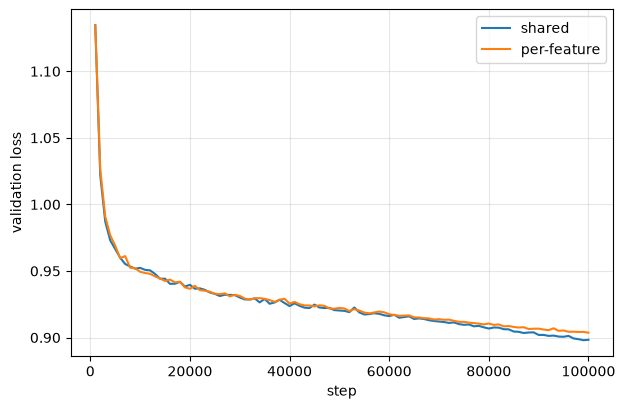

In [10]:
groups = {}
for run, r in R.items():
    key = (tuple(r["checkpoint"].get("val_files", [])), tuple(r["names"]), r["hparams"]["mask_type"])
    groups.setdefault(key, []).append(run)
for members in groups.values():
    if len(members) < 2:
        print(f"{label(members[0])}: no comparable run (validation files, variables or mask type differ)")
        continue
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for run in members:
        h = np.load(f"{input_dir}{run}/{run}_loss_history.npz")
        ax.plot(h["step"], h["val_loss"], label=label(run))
    ax.set_xlabel("step"); ax.set_ylabel("validation loss")
    ax.legend(); ax.grid(alpha=0.3)
    plt.show()
    # save_fig(fig, "E1_val_loss_" + "_".join(members))

## E2. Test loss per by-modality mask (runs with the same variables)
`<run> - <ref>`: difference of the mean losses, `± SE`: its standard error from the per-point differences
(same points, same noise). |difference| > ~2 SE: a real difference, not noise.

In [11]:
for members in same_vars.values():
    if len(members) < 2:
        continue
    ref = members[0]
    rows = {}
    for m, job in loss_jobs[ref].items():
        if m.startswith("ref "):   # E2b
            continue
        row = {"unknowns": int((~job["known"]).sum())}
        for run in members:
            row[label(run)] = losses[run][m].mean().item()
        for run in members[1:]:
            d = losses[run][m] - losses[ref][m]
            row[f"{label(run)} - {label(ref)}"] = d.mean().item()
            row[f"± SE ({label(run)})"] = (d.std() / len(d) ** 0.5).item()
        rows[m] = row
    table_e2 = pd.DataFrame(rows).T
    table_e2["unknowns"] = table_e2["unknowns"].astype(int)
    display(table_e2.round(4))

,unknowns,shared,per-feature,per-feature - shared,± SE (per-feature)
"known: - | gen: dark_matter, spheno_electroweakino_mass, spheno_higgs_mass, theory_parameter",20,1.2106,1.2103,-0.0003,0.0001
"known: dark_matter | gen: spheno_electroweakino_mass, spheno_higgs_mass, theory_parameter",19,1.1452,1.1448,-0.0004,0.0001
"known: spheno_electroweakino_mass | gen: dark_matter, spheno_higgs_mass, theory_parameter",14,1.0552,1.0764,0.0211,0.0002
"known: dark_matter, spheno_electroweakino_mass | gen: spheno_higgs_mass, theory_parameter",13,1.0786,1.0975,0.0189,0.0003
"known: spheno_higgs_mass | gen: dark_matter, spheno_electroweakino_mass, theory_parameter",19,1.1824,1.1822,-0.0003,0.0001
"known: dark_matter, spheno_higgs_mass | gen: spheno_electroweakino_mass, theory_parameter",18,1.1131,1.1127,-0.0003,0.0001
"known: spheno_electroweakino_mass, spheno_higgs_mass | gen: dark_matter, theory_parameter",13,1.0196,1.0340,0.0144,0.0002
"known: dark_matter, spheno_electroweakino_mass, spheno_higgs_mass | gen: theory_parameter",12,1.0459,1.0590,0.0131,0.0002
"known: theory_parameter | gen: dark_matter, spheno_electroweakino_mass, spheno_higgs_mass",8,0.0160,0.0159,-0.0002,0.0001
"known: dark_matter, theory_parameter | gen: spheno_electroweakino_mass, spheno_higgs_mass",7,0.0108,0.0105,-0.0003,0.0001


In [12]:
# ---- E2b. The masks of the reference run (runs[0], the benchmark) in every run ----------------
# Same modalities known as in the reference run; runs with more variables generate their extra variables
# too, and the loss is taken only on the reference run's unknown variables. Between runs with different
# variables this is only roughly comparable (different joint flow, no paired noise): mean ± SE per run.
print("Note that the first two rows aren't really comparable, since the models with more variables would receive information from other modalities.")
rows = {}
for m in modality_masks(R[ref_run]["variables"]):
    row = {}
    for run in runs:
        if f"ref {m}" in losses[run]:
            l = losses[run][f"ref {m}"]
            row[label(run)] = l.mean().item()
            row[f"± SE ({label(run)})"] = (l.std() / len(l) ** 0.5).item()
    rows[m] = row
display(pd.DataFrame(rows).T.round(4))

Note that the first two rows aren't really comparable, since the models with more variables would receive information from other modalities.


,benchmark,± SE (benchmark),shared,± SE (shared),per-feature,± SE (per-feature)
"known: - | gen: dark_matter, theory_parameter",1.4860,0.0011,1.3418,0.0011,1.3416,0.0011
known: dark_matter | gen: theory_parameter,1.4687,0.0012,1.3401,0.0011,1.3399,0.0011
known: theory_parameter | gen: dark_matter,0.0329,0.0005,0.0513,0.0006,0.0509,0.0006


## E3. Joint distribution (1D marginals)

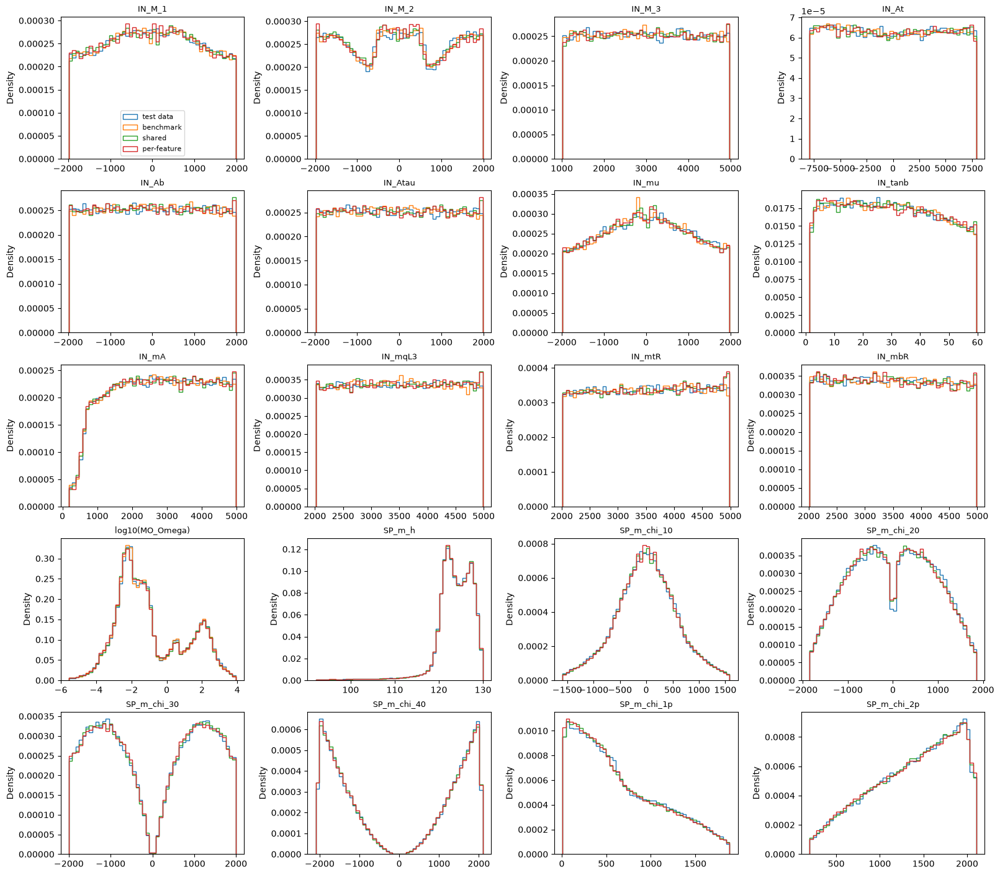

In [13]:
samples = {"test data": (np.column_stack([truth[n] for n in all_names]), all_names)}
for run, r in R.items():
    samples[label(run)] = (to_physical(r, results[run]["joint"], r["names"]), r["names"])
fig = plot_marginals(samples)

## E4. Inputs -> observables (observables in at least two runs)

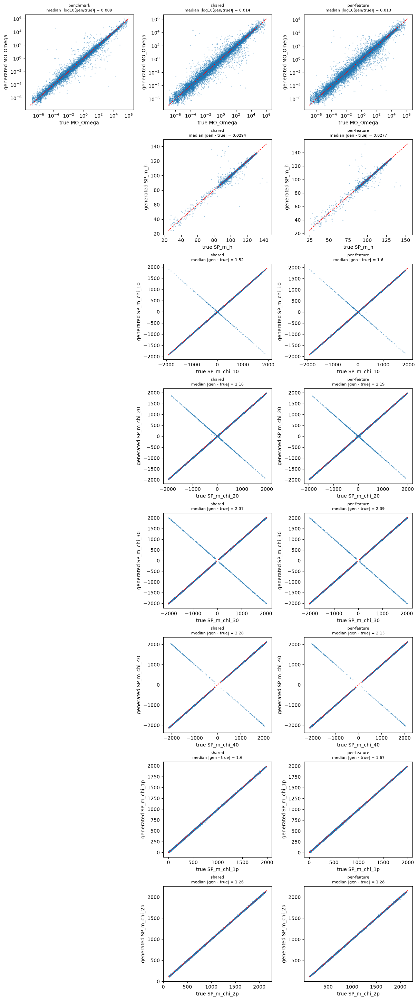

In [14]:
counts = {}
for r in R.values():
    for n in r["observables"]:
        counts[n] = counts.get(n, 0) + 1
features = [n for n in all_names if counts.get(n, 0) >= 2]
pairs = {label(run): (to_physical(r, results[run]["inputs_known"], r["observables"]),
                      np.column_stack([truth[n] for n in r["observables"]]), r["observables"])
         for run, r in R.items() if "inputs_known" in results[run]}
fig = plot_pred_vs_truth(pairs, variables=features)

## E5. Inputs given Omega = omega_0, m_h = m_h0, and both

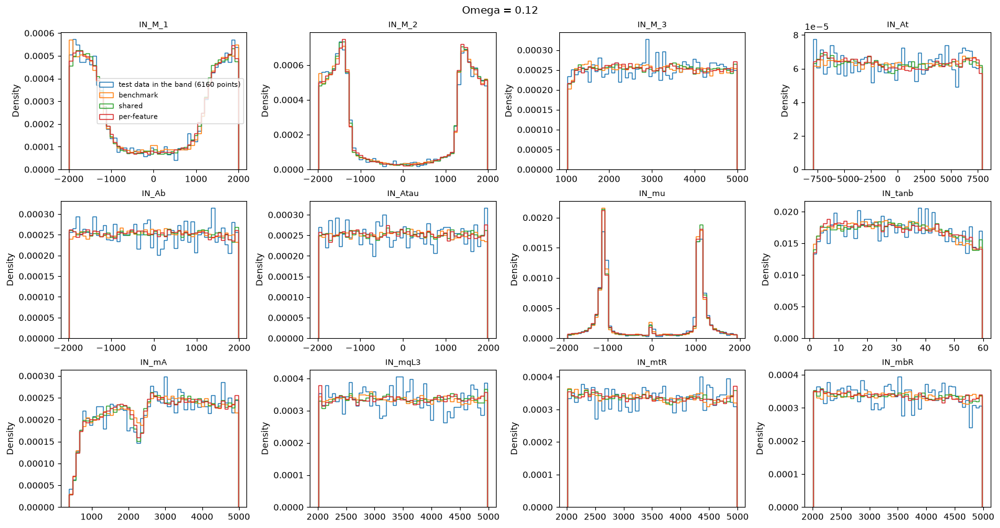

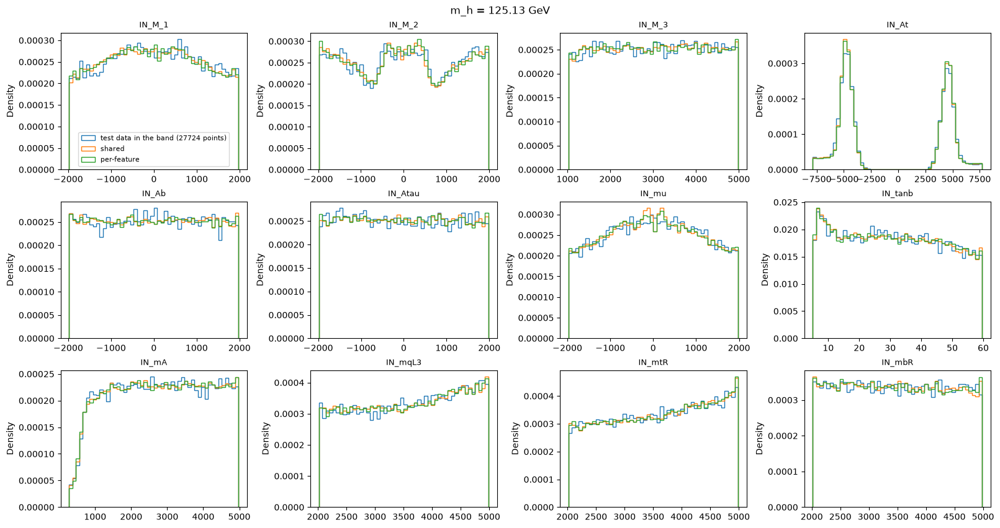

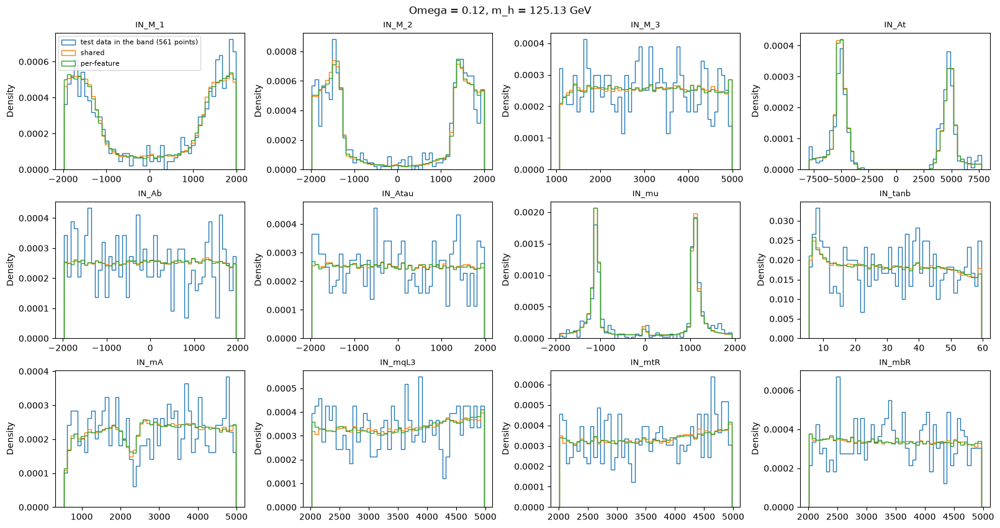

In [15]:
inputs = R[runs[0]]["inputs"]
omega_band = np.abs(np.log10(truth_all["MO_Omega"] / omega_0)) < d_log_omega
higgs_band = np.abs(truth_all["SP_m_h"] - m_h0) < d_m_h if "SP_m_h" in truth_all else None
cases = [("omega_fixed", omega_band, f"Omega = {omega_0}"),
         ("higgs_fixed", higgs_band, f"m_h = {m_h0} GeV"),
         ("omega_higgs_fixed", None if higgs_band is None else omega_band & higgs_band, f"Omega = {omega_0}, m_h = {m_h0} GeV")]
figs_e5 = {}   # job name -> figure, e.g. save_fig(figs_e5["higgs_fixed"], "E5_higgs_fixed")
for job, band, title in cases:
    if band is None:
        continue
    samples = {f"test data in the band ({band.sum()} points)": (np.column_stack([truth_all[n][band] for n in inputs]), inputs)}
    for run, r in R.items():
        if job in results[run]:
            samples[label(run)] = (to_physical(r, results[run][job], r["inputs"]), r["inputs"])
    figs_e5[job] = plot_marginals(samples)
    figs_e5[job].suptitle(title)
    plt.show()

## E6. Electroweakino masses and Omega (runs with electroweakino masses)

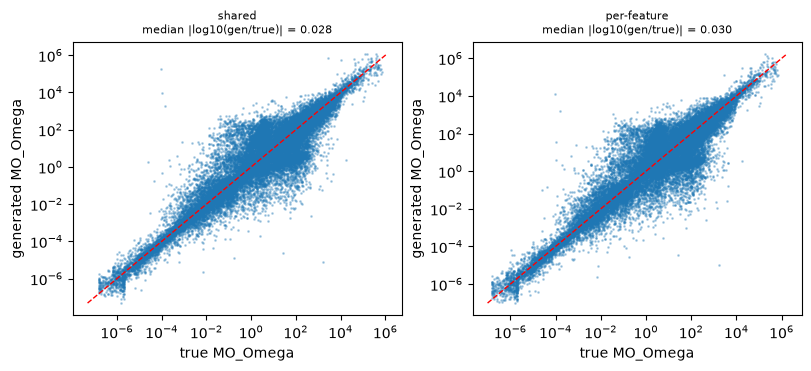

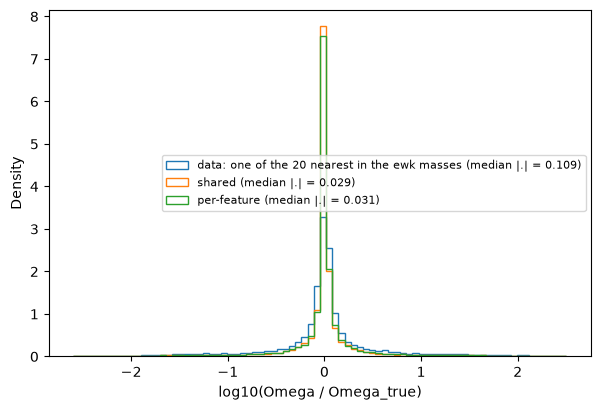

In [16]:
ewk_runs = [run for run in runs if R[run]["ewk"]]
ewk = R[ewk_runs[0]]["ewk"]

# a) Omega generated from the electroweakino masses (the other variables unknown)
pairs = {label(run): (to_physical(R[run], results[run]["omega_from_ewk"], ["MO_Omega"]), truth["MO_Omega"][:, None], ["MO_Omega"])
         for run in ewk_runs}
fig = plot_pred_vs_truth(pairs)
plt.show()

# data spread at fixed electroweakino masses: Omega of one random of the k nearest test points
# in the (standardized) electroweakino masses, compared with the generated Omega
k, n_knn = 20, min(20_000, n_sel)
X = torch.as_tensor(np.column_stack([truth_all[n] for n in ewk]), dtype=torch.float32)
X = (X - X.mean(0)) / X.std(0)
q = torch.as_tensor(sel[:n_knn])
g = torch.Generator().manual_seed(0)
neighbour = torch.empty(n_knn, dtype=torch.long)
for s in range(0, n_knn, 256):
    idx = torch.cdist(X[q[s:s + 256]], X).topk(k + 1, largest=False).indices[:, 1:]   # without the point itself
    neighbour[s:s + 256] = idx[torch.arange(len(idx)), torch.randint(k, (len(idx),), generator=g)]
omega_true = truth_all["MO_Omega"][sel[:n_knn]]
ratios = {f"data: one of the {k} nearest in the ewk masses": np.log10(truth_all["MO_Omega"][neighbour.numpy()] / omega_true)}
for run in ewk_runs:
    ratios[label(run)] = np.log10(pairs[label(run)][0][:n_knn, 0] / omega_true)
fig_spread, ax = plt.subplots(figsize=(7, 4.5))
rng = np.percentile(np.concatenate(list(ratios.values())), [0.5, 99.5])
for name, x in ratios.items():
    ax.hist(x, bins=80, range=rng, density=True, histtype='step', label=f"{name} (median |.| = {np.median(np.abs(x)):.3f})")
ax.set_xlabel("log10(Omega / Omega_true)"); ax.set_ylabel("Density"); ax.legend(fontsize=8)
plt.show()

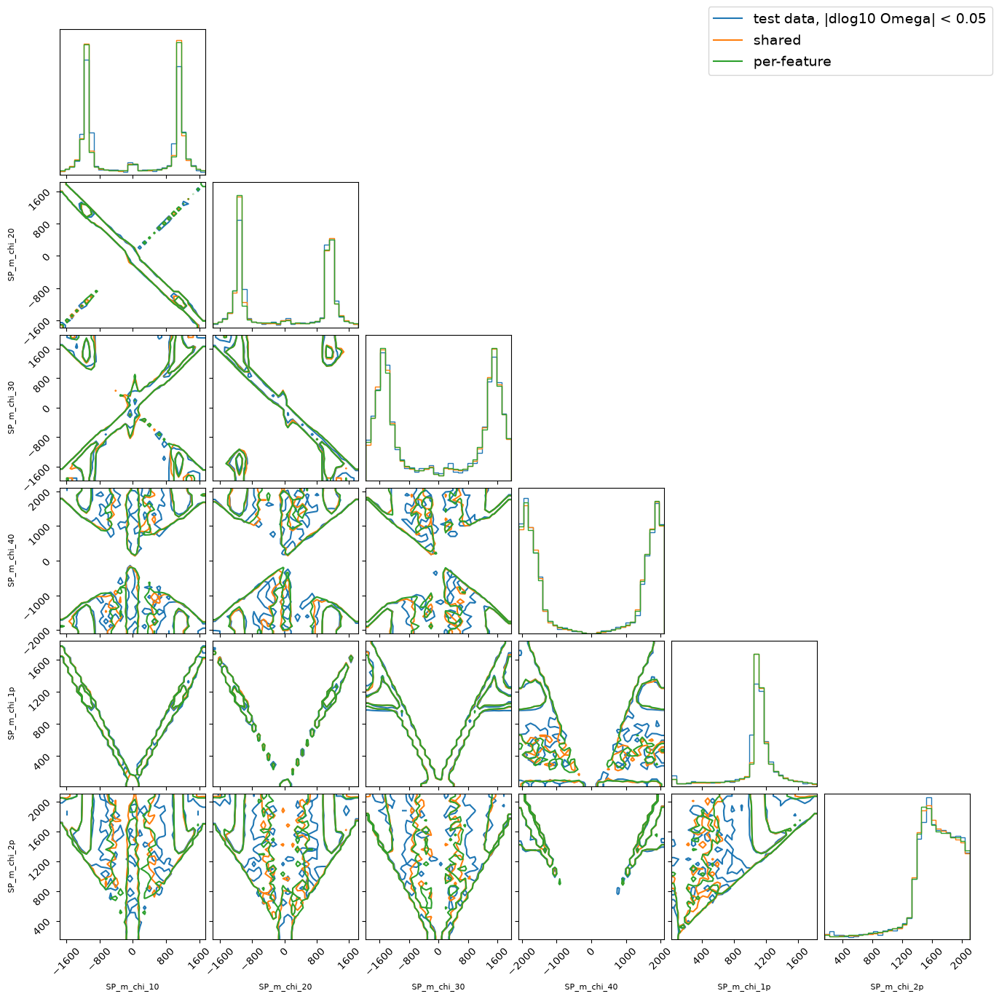

In [17]:
# b) electroweakino masses given Omega = omega_0
samples = {f"test data, |dlog10 Omega| < {d_log_omega}": (np.column_stack([truth_all[n][omega_band] for n in ewk]), ewk)}
for run in ewk_runs:
    samples[label(run)] = (to_physical(R[run], results[run]["ewk_given_omega_fixed"], ewk), ewk)
fig = plot_corner(samples)

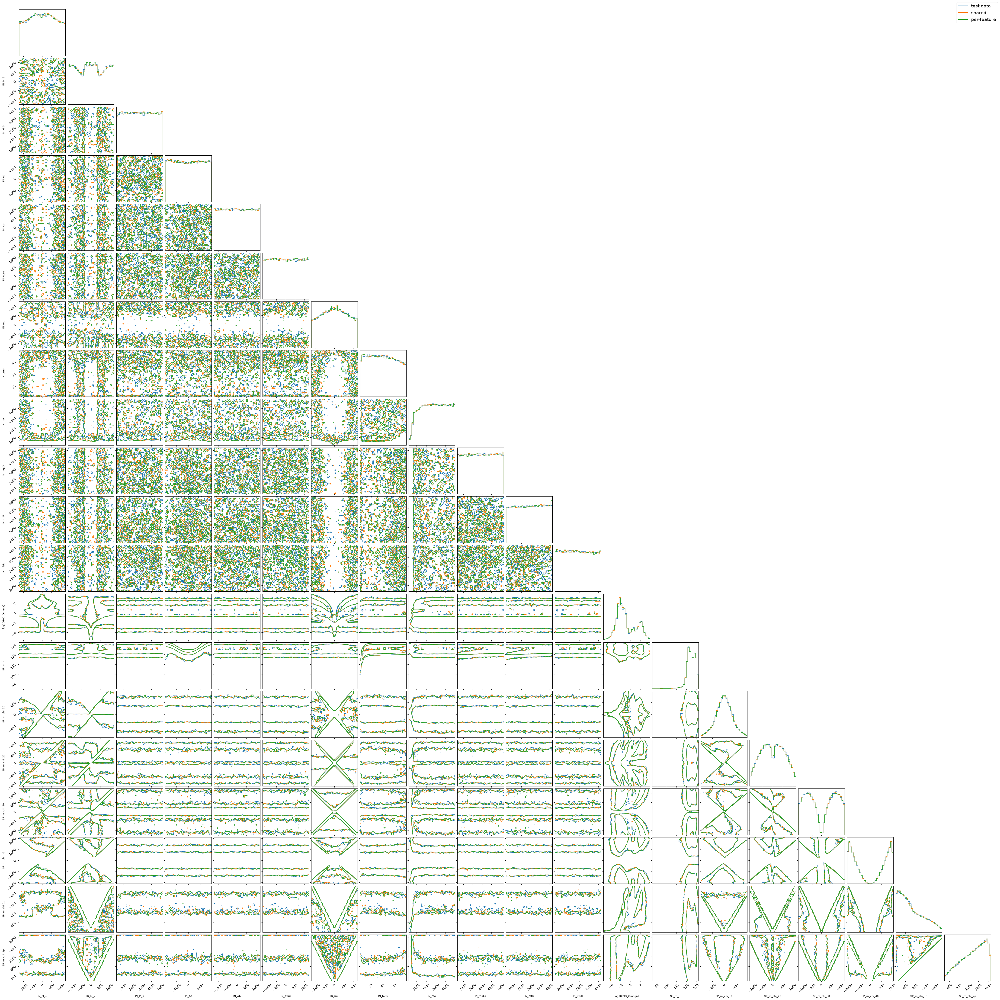

In [18]:
# c) joint distribution (all variables of the electroweakino runs; variables=... to shrink)
samples = {"test data": (np.column_stack([truth[n] for n in all_names]), all_names)}
for run in ewk_runs:
    samples[label(run)] = (to_physical(R[run], results[run]["joint"], R[run]["names"]), R[run]["names"])
fig = plot_corner(samples)

## E7. Numbers for the text (from the existing samples, nothing is sampled again)
**a)** Observables generated from the inputs (`inputs_known`), compared with the true value of the same test point.
Omega: median |log10(generated / true)|, fraction within 10 % and within a factor of 2. Other observables: median absolute
and relative error, fraction with the correct sign (the neutralino masses are signed).
**b)** KS distance (largest gap between the cumulative distributions, 0 = identical) between generated and test data, per
variable. `chance level`: KS between two random halves of the test data, i.e. the gap that statistics alone produces;
values around or below it mean "no visible difference". KS only compares 1D marginals, not correlations.

In [8]:
# ---- E7. Numbers for the text ----------------------------------------------------------------
from scipy.stats import ks_2samp

# a) observables from the inputs, per test point
omega_rows, other_rows = {}, {}
for run, r in R.items():
    if "inputs_known" not in results[run]:
        continue
    gen = to_physical(r, results[run]["inputs_known"], r["observables"])
    for k, n in enumerate(r["observables"]):
        g, t = gen[:, k], truth[n]
        if n == "MO_Omega":
            d = np.abs(np.log10(g / t))
            omega_rows[label(run)] = {"median |dlog10 Omega|": np.median(d), "within 10%": np.mean(d < np.log10(1.1)),
                                      "within factor 2": np.mean(d < np.log10(2))}
        else:
            other_rows[(label(run), n)] = {"median |gen - true|": np.median(np.abs(g - t)),
                                           "median rel. error": np.median(np.abs(g - t) / np.abs(t)),
                                           "sign correct": np.mean(np.sign(g) == np.sign(t))}
print("a) Omega from the inputs")
display(pd.DataFrame(omega_rows).T.round(4))
if other_rows:
    print("a) other observables from the inputs")
    display(pd.DataFrame(other_rows).T.round(4))

# b) KS distances, generated vs test data
def ks_table(data, gens, names, seed=1):
    '''data: {name: test values}; gens: {label: (array, names)}. KS per variable and the chance level
    (KS between two random halves of the test values). KS does not change under log10, so Omega needs no log.'''
    rng = np.random.default_rng(seed)
    rows = {}
    for n in names:
        d = data[n]
        p = rng.permutation(len(d))
        row = {"chance level": ks_2samp(d[p[:len(d) // 2]], d[p[len(d) // 2:]]).statistic}
        for lab_, (x, xnames) in gens.items():
            if n in xnames:
                row[lab_] = ks_2samp(x[:, xnames.index(n)], d).statistic
        rows[n] = row
    return pd.DataFrame(rows).T.round(4)

print(f"b) joint distribution: unconditional samples vs the {n_sel} selected test points")
display(ks_table(truth, {label(run): (to_physical(r, results[run]["joint"], r["names"]), r["names"]) for run, r in R.items()},
                 all_names))

inputs = R[runs[0]]["inputs"]
omega_band = np.abs(np.log10(truth_all["MO_Omega"] / omega_0)) < d_log_omega
higgs_band = np.abs(truth_all["SP_m_h"] - m_h0) < d_m_h if "SP_m_h" in truth_all else None
cases = [("omega_fixed", omega_band, f"Omega = {omega_0}"),
         ("higgs_fixed", higgs_band, f"m_h = {m_h0} GeV"),
         ("omega_higgs_fixed", None if higgs_band is None else omega_band & higgs_band, f"Omega = {omega_0}, m_h = {m_h0} GeV")]
for job, band, title in cases:
    gens = {label(run): (to_physical(r, results[run][job], r["inputs"]), r["inputs"])
            for run, r in R.items() if band is not None and job in results[run]}
    if gens:
        print(f"b) inputs given {title}: generated vs the {band.sum()} test points in the band")
        display(ks_table({n: truth_all[n][band] for n in inputs}, gens, inputs))

a) Omega from the inputs


,median |dlog10 Omega|,within 10%,within factor 2
benchmark,0.0093,0.7947,0.9737
shared,0.0138,0.7355,0.9483
per-feature,0.0130,0.7445,0.9489


a) other observables from the inputs


median |gen - true|  median rel. error  sign correct
shared      SP_m_h                    0.0294             0.0002        1.0000
            SP_m_chi_10               1.5227             0.0040        0.9963
            SP_m_chi_20               2.1578             0.0030        0.9946
            SP_m_chi_30               2.3660             0.0021        0.9943
            SP_m_chi_40               2.2788             0.0015        0.9974
            SP_m_chi_1p               1.5964             0.0030        0.9998
            SP_m_chi_2p               1.2617             0.0009        1.0000
per-feature SP_m_h                    0.0277             0.0002        1.0000
            SP_m_chi_10               1.5969             0.0042        0.9957
            SP_m_chi_20               2.1884             0.0030        0.9944
            SP_m_chi_30               2.3881             0.0021        0.9946
            SP_m_chi_40               2.1295             0.0014        0.9976
            SP_m_chi_1p               1.6716             0.0031        1.0000
            SP_m_chi_2p               1.2828             0.0009        1.0000

b) joint distribution: unconditional samples vs the 100000 selected test points


,chance level,benchmark,shared,per-feature
IN_M_1,0.0047,0.0023,0.0042,0.0031
IN_M_2,0.0041,0.0047,0.0079,0.0107
IN_M_3,0.0078,0.0038,0.0045,0.0024
IN_At,0.0056,0.0028,0.0038,0.0042
IN_Ab,0.0068,0.0051,0.0037,0.0034
IN_Atau,0.0041,0.0065,0.0053,0.0045
IN_mu,0.0051,0.0057,0.0080,0.0088
IN_tanb,0.0056,0.0039,0.0032,0.0067
IN_mA,0.0048,0.0019,0.0029,0.0035
IN_mqL3,0.0043,0.0062,0.0035,0.0035


... (2 outputs left out)

b) inputs given m_h = 125.13 GeV: generated vs the 27724 test points in the band


,chance level,shared,per-feature
IN_M_1,0.0112,0.0086,0.0086
IN_M_2,0.0151,0.0101,0.0105
IN_M_3,0.0112,0.0038,0.0062
IN_At,0.0108,0.0145,0.0169
IN_Ab,0.0069,0.0071,0.0075
IN_Atau,0.0143,0.0084,0.0075
IN_mu,0.0130,0.0115,0.0104
IN_tanb,0.0056,0.0071,0.0058
IN_mA,0.0134,0.0049,0.0051
IN_mqL3,0.0057,0.0134,0.0102


b) inputs given Omega = 0.12, m_h = 125.13 GeV: generated vs the 561 test points in the band


,chance level,shared,per-feature
IN_M_1,0.1062,0.0461,0.0444
IN_M_2,0.0455,0.0335,0.0310
IN_M_3,0.0702,0.0316,0.0271
IN_At,0.1046,0.0454,0.0439
IN_Ab,0.0666,0.0487,0.0482
IN_Atau,0.0796,0.0331,0.0332
IN_mu,0.0949,0.0625,0.0655
IN_tanb,0.0502,0.0317,0.0317
IN_mA,0.0690,0.0395,0.0400
IN_mqL3,0.0595,0.0340,0.0289
